In [2]:
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
df=sns.load_dataset('titanic')
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [4]:
df.isnull().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [26]:
# find mean age of passengers of each class, group by class and alive
df.groupby(['class', 'alive'])['age'].mean()

class   alive
First   no       43.695312
        yes      35.368197
Second  no       33.544444
        yes      25.901566
Third   no       26.555556
        yes      20.646118
Name: age, dtype: float64

In [27]:
df['class_mean_age'] = df.groupby('class')['age'].transform('mean')

df[['class', 'alive', 'class_mean_age']]

,class,alive,class_mean_age
0,Third,no,25.140620
1,First,yes,38.233441
2,Third,yes,25.140620
3,First,yes,38.233441
4,Third,no,25.140620
...,...,...,...
886,Second,no,29.877630
887,First,yes,38.233441
888,Third,no,25.140620
889,First,yes,38.233441


In [12]:
# find unique values in alive column
df['alive'].unique()
df['alive'].value_counts()

alive
no     549
yes    342
Name: count, dtype: int64

<Axes: >

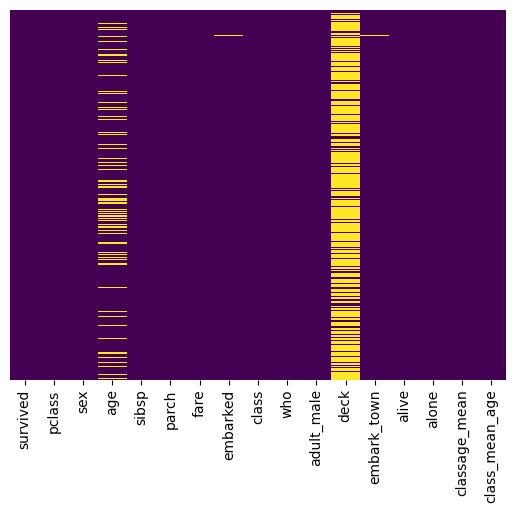

In [29]:
sns.heatmap(df.isnull(),yticklabels=False,cbar=False,cmap='viridis')

```python
sns.heatmap(df.isnull(), yticklabels=False, cbar=False, cmap='viridis')
```

**Purpose:** Visualize missing values in a dataset.

* `df.isnull()` → marks missing values as `True` and others as `False`.
* `heatmap()` → displays these values as colors.
* `yticklabels=False` → hides row labels.
* `cbar=False` → removes the color legend.
* `cmap='viridis'` → sets the color scheme.

**Why it helps:** Quickly identifies which columns and rows contain missing data and reveals any missing-value patterns.


Roughly 20 percent of the Age data is missing. The proportion of Age missing is likely small enough for reasonable replacement with some form of imputation. Looking at the deck column, it looks like we are just missing too much of that data to do something useful with at a basic level. We'll probably drop this later, or change it to another feature like "deck Known: 1 or 0"

Let's continue on by visualizing some more of the data! Check out the video for full explanations over these plots, this code is just to serve as reference.

In [37]:
# percentage of null values in each column
(df.isnull().sum()/len(df)).sort_values(ascending=False)

deck              0.772166
age               0.198653
embark_town       0.002245
embarked          0.002245
survived          0.000000
adult_male        0.000000
classage_mean     0.000000
alone             0.000000
alive             0.000000
class             0.000000
who               0.000000
pclass            0.000000
fare              0.000000
parch             0.000000
sibsp             0.000000
sex               0.000000
class_mean_age    0.000000
dtype: float64

<Axes: xlabel='survived', ylabel='count'>

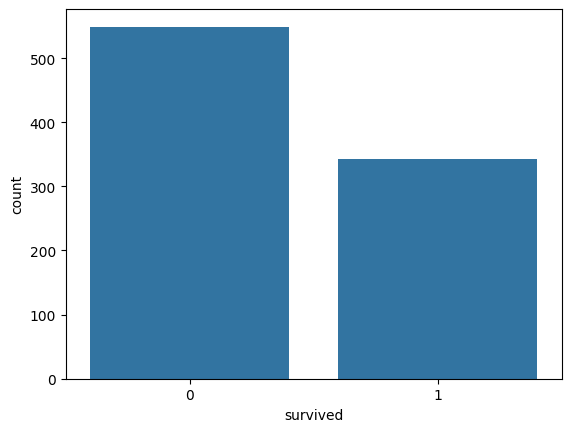

In [39]:
sns.countplot(x='survived', data=df)

Purpose: Visualize the frequency of each category in the survived column.

x='survived' → column to analyze.
data=df → DataFrame containing the data.
countplot() → creates bars showing the count of each category.

Why it helps: Quickly shows the distribution of survivors vs. non-survivors and helps identify class imbalance in the dataset.

<Axes: xlabel='survived', ylabel='count'>

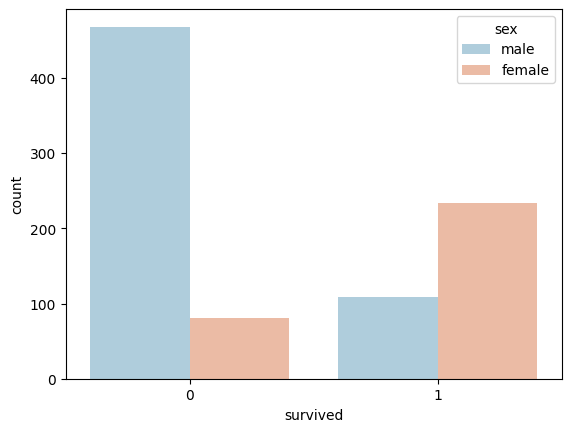

In [43]:
sns.countplot(x='survived',hue='sex',data=df,palette='RdBu_r')

```python
sns.countplot(x='survived', hue='sex', data=df, palette='RdBu_r')
```

**Purpose:** Compare survival counts by gender.

* `x='survived'` → groups data into survived and not survived.
* `hue='sex'` → splits each group by gender.
* `data=df` → DataFrame containing the data.
* `palette='RdBu_r'` → sets the bar colors.

**Why it helps:** Quickly shows how survival rates differed between males and females.


# NOTE
hue can only take one feature, but you can combine features or use faceting (row/col) to visualize multiple categorical variables together.

<Axes: xlabel='survived', ylabel='count'>

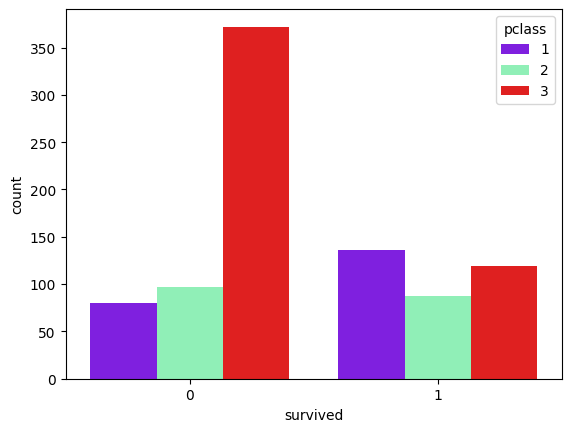

In [47]:
sns.countplot(x='survived',hue='pclass',data=df,palette='rainbow')

### From people survived, passanger class 1 and 3 have survived a lot

<Axes: xlabel='age', ylabel='Count'>

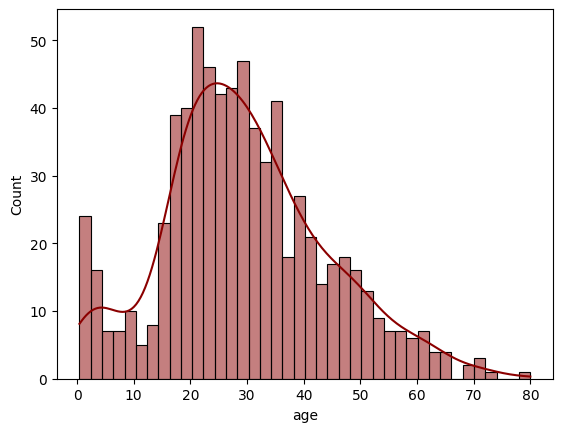

In [52]:
sns.histplot(df['age'].dropna(),kde=True,color='darkred',bins=40)

```python
sns.histplot(df['age'].dropna(), kde=True, color='darkred', bins=40)
```

**Purpose:** Visualize the distribution of passengers' ages using a histogram and a density curve.

* `df['age']` → selects the `age` column.
* `.dropna()` → removes missing (`NaN`) age values.
* `histplot()` → creates a histogram showing the frequency of ages.
* `kde=True` → overlays a smooth density curve (Kernel Density Estimate).
* `color='darkred'` → sets the histogram and KDE color to dark red.
* `bins=40` → divides the age range into 40 intervals (bars).

**Why it helps:** It shows both the frequency distribution of ages and the overall shape of the age distribution (e.g., peaks, spread, skewness) in a single plot.


<Axes: xlabel='age', ylabel='Count'>

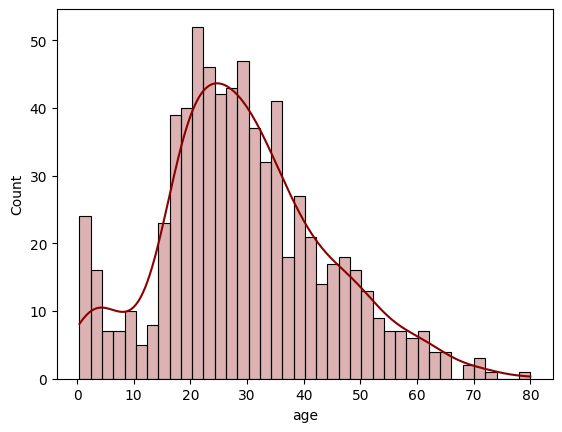

In [53]:
sns.histplot(
    df['age'].dropna(),
    kde=True,
    color='darkred',
    bins=40,
    alpha=0.3
)

```python
sns.histplot(
    df['age'].dropna(),
    kde=True,
    color='darkred',
    bins=40,
    alpha=0.3
)
```

**Purpose:** Visualize the age distribution with a semi-transparent histogram and a density curve.

* `df['age']` → selects the age column.
* `.dropna()` → removes missing age values.
* `kde=True` → adds a smooth density (KDE) curve.
* `color='darkred'` → sets the plot color.
* `bins=40` → divides the age range into 40 bars.
* `alpha=0.3` → makes the histogram bars 30% opaque (70% transparent).

**Why it helps:** The transparency (`alpha=0.3`) makes the bars less visually dominant, allowing the KDE curve and overlapping plot elements to be seen more clearly.


<Axes: xlabel='sibsp', ylabel='count'>

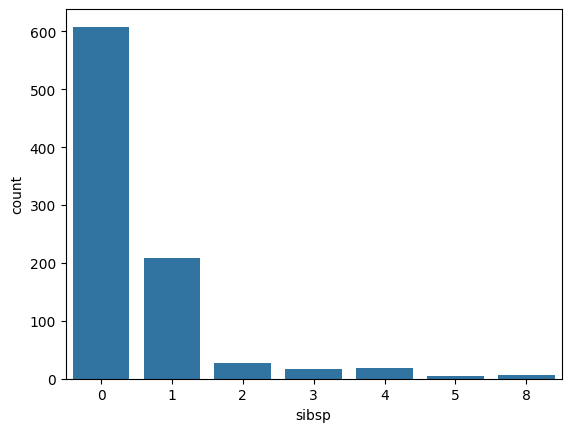

In [54]:
sns.countplot(x='sibsp',data=df)

```python
sns.countplot(x='sibsp', data=df)
```

**Purpose:** Show the distribution of passengers based on the number of siblings/spouses they had aboard the Titanic.

* `x='sibsp'` → uses the `sibsp` column (number of siblings/spouses aboard).
* `data=df` → DataFrame containing the Titanic data.
* `countplot()` → creates bars showing the count of passengers for each `sibsp` value.

**Why it helps:** Quickly reveals how many passengers traveled alone (`sibsp=0`) versus with 1, 2, 3, etc., siblings/spouses, helping identify family-size patterns in the dataset.


<Axes: >

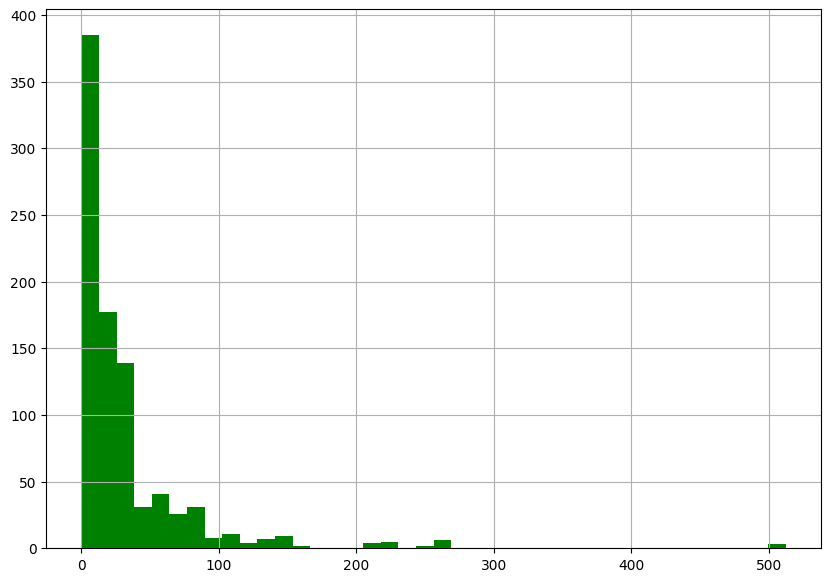

In [58]:
df['fare'].hist(bins=40,color='green',figsize=(10,7))

```python
df['fare'].hist(bins=40, color='green', figsize=(10,7))
```

**Purpose:** Create a histogram to visualize the distribution of passenger fares.

* `df['fare']` → selects the `fare` column.
* `.hist()` → generates a histogram.
* `bins=40` → divides the fare range into 40 intervals (bars).
* `color='green'` → colors the bars green.
* `figsize=(10,7)` → sets the plot size to 10×7 inches.

**Why it helps:** Shows how fares are distributed, helping identify common fare ranges, spread, skewness, and potential outliers.


# Data Cleaning

We want to fill in missing age data instead of just dropping the missing age data rows. One way to do this is by filling in the mean age of all the passengers (imputation). However we can be smarter about this and check the average age by passenger class. For example:

/var/folders/2x/xmh08hhn4jz6qfgvnkk3pldw0000gn/T/ipykernel_39978/3675082444.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='pclass',y='age',data=df,palette='winter')


<Axes: xlabel='pclass', ylabel='age'>

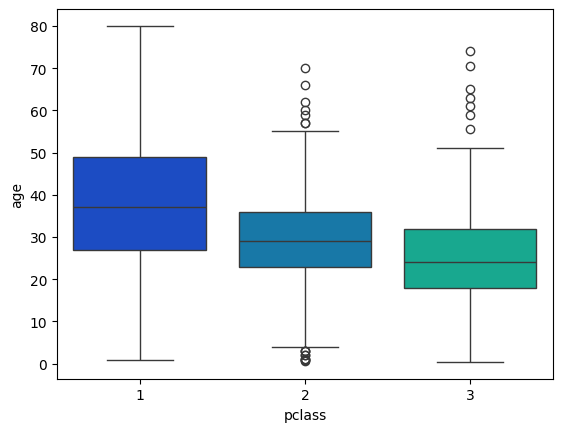

In [67]:
sns.boxplot(x='pclass',y='age',data=df,palette='winter')

We can see the wealthier passengers in the higher classes tend to be older, which makes sense. We'll use these average age values to impute based on Pclass for Age.

In [82]:
class_age = df.groupby('pclass')['age'].mean()

def impute_age(cols):
    age = cols[0]
    pclass = cols[1]

    if pd.isnull(age):
        return class_age[pclass]
    else:
        return age

In [84]:

# Calculate mean age for each passenger class
class_age = df.groupby('pclass')['age'].mean()

# Function to fill missing ages
def impute_age(row):
    age = row['age']
    pclass = row['pclass']

    if pd.isnull(age):
        return class_age[pclass]
    else:
        return age

# Apply the function row-wise and update the age column
df['age'] = df[['age', 'pclass']].apply(impute_age, axis=1)

In [83]:
df['age'] = df[['age','pclass']].apply(impute_age, axis=1)

KeyError: 0

In [64]:
df['fare'].iplot(kind='hist',bins=30,color='green')

ValueError: 
    Invalid value of type 'builtins.str' received for the 'color' property of histogram.marker
        Received value: 'rgba(0, 128, 0, np.float64(1.0))'

    The 'color' property is a color and may be specified as:
      - A hex string (e.g. '#ff0000')
      - An rgb/rgba string (e.g. 'rgb(255,0,0)')
      - An hsl/hsla string (e.g. 'hsl(0,100%,50%)')
      - An hsv/hsva string (e.g. 'hsv(0,100%,100%)')
      - A named CSS color: see https://plotly.com/python/css-colors/ for a list
      - A number that will be interpreted as a color
        according to histogram.marker.colorscale
      - A list or array of any of the above